# <span style="color:green"> Laboratorio di Simulazione Numerica </span>
## <span style="color:blue">  Tommaso Cardano Chiezzi</span>

## Esercizio 07.1 — Tail corrections

Nel sistema di Lennard-Jones, ogni coppia di particelle interagisce tramite il potenziale

$$
v(r)=4\left[\frac{1}{r^{12}}-\frac{1}{r^6}\right],
$$

dove $r$ è la distanza tra le due particelle.

In una simulazione sarebbe possibile, in principio, calcolare l'interazione tra tutte le coppie di particelle. Tuttavia, il numero di coppie cresce come $N(N-1)/2$, rendendo il calcolo molto costoso per sistemi grandi. Inoltre, il potenziale di Lennard-Jones è a corto raggio: per grandi distanze il termine repulsivo $1/r^{12}$ diventa trascurabile molto rapidamente e anche il termine attrattivo $1/r^6$ diminuisce con la distanza.

Per questo motivo si introduce un **raggio di cutoff** $r_c$ (si veda l'esercitazione 4): le interazioni vengono calcolate esplicitamente solo per

$$
r<r_c,
$$

mentre quelle a distanza maggiore vengono trascurate. Nelle simulazioni con condizioni periodiche, inoltre, il cutoff deve essere compatibile con la minimum image convention e viene normalmente scelto con $r_c\leq L/2$, dove $L$ è il lato della scatola di simulazione.

Le interazioni per $r>r_c$ sono però piccole, ma non esattamente nulle. Il loro contributo complessivo può quindi produrre una correzione non trascurabile all'energia potenziale e alla pressione.

Per stimare questo contributo si assume che, a distanze sufficientemente grandi, le correlazioni tra le particelle siano ormai trascurabili:

$$
g(r)\simeq 1
\qquad \text{per } r>r_c,
$$

dove $g(r)$ è la funzione di distribuzione radiale.

La correzione di coda dell'energia potenziale per particella risulta

$$
\boxed{
\frac{U_{\mathrm{tail}}}{N}
=
8\pi\rho
\left[
\frac{1}{9r_c^9}
-
\frac{1}{3r_c^3}
\right]
},
$$

mentre la correzione alla pressione è

$$
\boxed{
P_{\mathrm{tail}}
=
32\pi\rho^2
\left[
\frac{1}{9r_c^9}
-
\frac{1}{6r_c^3}
\right]
}.
$$

Qui $\rho=N/V$ è la densità numerica del sistema. Le tail corrections permettono quindi di mantenere il vantaggio computazionale del cutoff, recuperando in modo approssimato il contributo delle interazioni a lunga distanza che non vengono calcolate direttamente.

Il simulatore è stato quindi modificato introducendo queste due correzioni, in modo da includere anche il contributo medio delle interazioni trascurate oltre il cutoff $r_c$ nel calcolo dell'energia potenziale e della pressione.

# Esercizio 07.2 — Equilibrazione e analisi statistica

Si considera un sistema di $N=256$ particelle interagenti tramite il potenziale di Lennard-Jones, nella fase liquida e nelle condizioni

$$
\rho^*=0.8,
\qquad
T^*=1.1,
\qquad
r_c^*=2.5.
$$

L'obiettivo è confrontare una simulazione Monte Carlo nell'ensemble $NVT$ con una simulazione di Molecular Dynamics nell'ensemble $NVE$.

Per entrambi i metodi, dopo una fase iniziale di equilibrazione, verranno prodotti

$$
M=5\times10^5
$$

valori istantanei dell'energia potenziale per particella $U/N$.

Prima della produzione è necessario verificare che il sistema abbia raggiunto l'equilibrio. Nel caso Monte Carlo viene inoltre regolata l'ampiezza delle mosse $\delta$ in modo da ottenere un acceptance ratio circa pari al $50\%$.

## Equilibrazione Monte Carlo

Per la simulazione Monte Carlo è stato utilizzato l'algoritmo di Metropolis con

$$
\delta=0.10.
$$

Una mossa proposta viene accettata con probabilità

$$
A=\min\left(1,e^{-\beta\Delta U}\right),
$$

dove:

- $\Delta U=U_{\mathrm{new}}-U_{\mathrm{old}}$ è la variazione di energia potenziale associata alla mossa;
- $\beta=1/T$ è l'inverso della temperatura ridotta.

Sono stati effettuati $2\times10^4$ step preliminari per verificare l'equilibrazione del sistema e il valore dell'acceptance ratio.

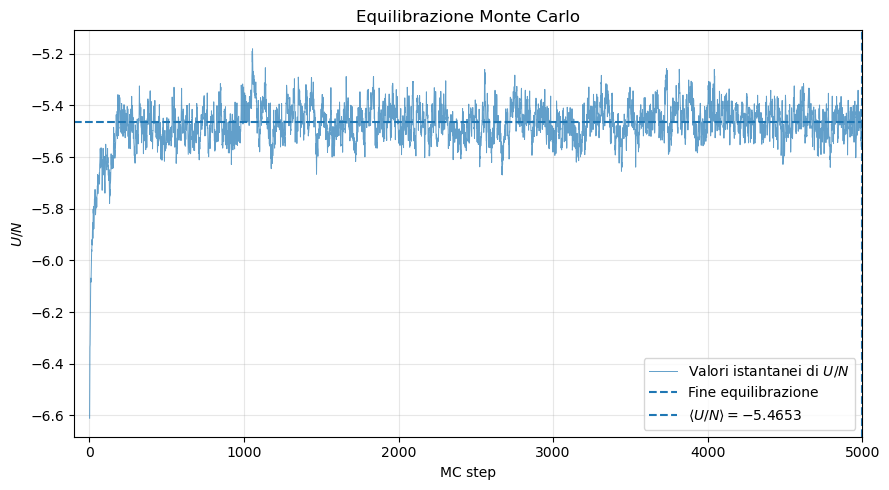

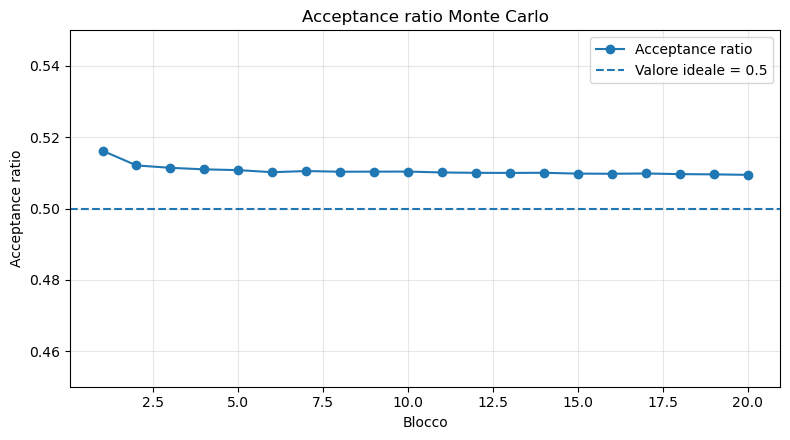

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Lettura dei valori istantanei di U/N
data = np.loadtxt("Esercizio_07.2/NSL_SIMULATOR/OUTPUT/instantaneous_potential_energy_MC_equilibration.dat", comments="#")

step = data[:, 0]
u = data[:, 1]

# Numero di step che consideriamo di equilibrazione
n_eq = 5000

# Media dopo l'equilibrazione
u_eq = np.mean(u[step > n_eq])

plt.figure(figsize=(9, 5))

plt.plot(step, u, linewidth=0.7, alpha=0.7,
         label=r"Valori istantanei di $U/N$")

plt.axvline(n_eq, linestyle="--",
            label="Fine equilibrazione")

plt.axhline(u_eq, linestyle="--",
            label=rf"$\langle U/N\rangle = {u_eq:.4f}$")

plt.xlabel("MC step")
plt.ylabel(r"$U/N$")
plt.title("Equilibrazione Monte Carlo")
plt.xlim(-100,5000)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

acc = np.loadtxt("Esercizio_07.2/NSL_SIMULATOR/OUTPUT/acceptance_MC_equilibration.dat", comments="#")

block = acc[:, 0]
acceptance = acc[:, 1]

plt.figure(figsize=(8, 4.5))

plt.plot(block, acceptance, marker="o",
         label="Acceptance ratio")

plt.axhline(0.5, linestyle="--",
            label="Valore ideale = 0.5")

plt.xlabel("Blocco")
plt.ylabel("Acceptance ratio")
plt.title("Acceptance ratio Monte Carlo")

plt.ylim(0.45, 0.55)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

### Commento sull'equilibrazione MC

Nel primo grafico si osserva un chiaro transiente iniziale: l'energia potenziale per particella parte da un valore molto basso e varia rapidamente nei primi step. Successivamente $U/N$ inizia a oscillare in modo stazionario attorno al valore medio

$$
\left\langle \frac{U}{N} \right\rangle \simeq -5.465.
$$


Il sistema può quindi essere considerato equilibrato già dopo circa $10^3$ step. Per la successiva simulazione di produzione si utilizza comunque la configurazione ottenuta al termine dell'intera fase preliminare, così da partire sicuramente da uno stato equilibrato.


Il secondo grafico mostra invece che l'acceptance ratio si stabilizza rapidamente intorno a

$$
A \simeq 0.51,
$$

molto vicino al valore desiderato del $50\%$. Il valore scelto $\delta=0.10$ rappresenta quindi un buon compromesso tra mosse troppo piccole, che produrrebbero configurazioni fortemente correlate, e mosse troppo grandi, che verrebbero frequentemente rifiutate.

La configurazione finale ottenuta dopo l'equilibrazione può quindi essere utilizzata come punto di partenza per la simulazione Monte Carlo di produzione.

## Autocorrelazione — Monte Carlo

Dopo l'equilibrazione sono stati prodotti

$$
M=5\times10^5
$$

valori istantanei dell'energia potenziale per particella $u_i=(U/N)_i$.

Poiché configurazioni Monte Carlo successive non sono statisticamente indipendenti, si calcola la funzione di autocorrelazione

$$
C(\tau)=
\frac{
\displaystyle
\frac{1}{M-\tau}
\sum_{i=1}^{M-\tau}
(u_i-\bar u)(u_{i+\tau}-\bar u)
}{
\displaystyle
\frac{1}{M}
\sum_{i=1}^{M}(u_i-\bar u)^2
},
$$

dove $\tau$ è il lag, cioè la distanza in MC step tra due misure, e $\bar u$ è il valore medio di $U/N$.

Per $\tau=0$ si ha $C(0)=1$, mentre per lag sufficientemente grandi l'autocorrelazione deve tendere a zero. L'andamento di $C(\tau)$ permette quindi di stimare quanto grandi debbano essere i blocchi affinché misure appartenenti a blocchi diversi siano sostanzialmente indipendenti.

Numero di misure = 500000
<U/N> = -5.461079


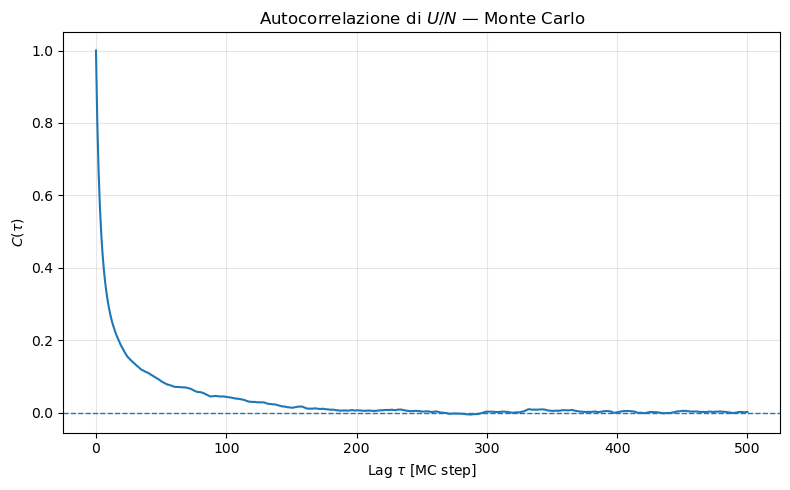

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Lettura della produzione MC
data_mc = np.loadtxt("Esercizio_07.2/NSL_SIMULATOR/OUTPUT/instantaneous_potential_energy_MC_production.dat", comments="#")

step_mc = data_mc[:, 0]
u_mc = data_mc[:, 1]

M = len(u_mc)

print("Numero di misure =", M)
print(f"<U/N> = {np.mean(u_mc):.6f}")


def autocorrelation(x, max_lag):

    x = x - np.mean(x)
    N = len(x)

    # Lunghezza della FFT
    nfft = 1 << (2*N - 1).bit_length()

    f = np.fft.rfft(x, n=nfft)

    acf = np.fft.irfft(f * np.conjugate(f), n=nfft)[:N]

    # Normalizzazione per il numero di coppie disponibili a ogni lag
    acf /= np.arange(N, 0, -1)

    # C(0) = 1
    acf /= acf[0]

    return acf[:max_lag + 1]


max_lag = 500

C_mc = autocorrelation(u_mc, max_lag)
tau = np.arange(max_lag + 1)

plt.figure(figsize=(8, 5))

plt.plot(tau, C_mc)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel(r"Lag $\tau$ [MC step]")
plt.ylabel(r"$C(\tau)$")
plt.title(r"Autocorrelazione di $U/N$ — Monte Carlo")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

## Incertezza statistica e dimensione dei blocchi

Per studiare l'effetto delle correlazioni sui dati, le $M$ misure vengono divise in $N$ blocchi contenenti ciascuno $L$ valori, con

$$
L=\frac{M}{N}.
$$

Per ogni blocco viene calcolata la media

$$
A_k=\frac{1}{L}\sum_{i=1}^{L}u_i,
$$

dove $A_k$ è la media di $U/N$ nel blocco $k$.

L'incertezza statistica sulla media è quindi stimata a partire dalla dispersione delle medie dei blocchi.

La dimensione $L$ viene variata tra

$$
10\leq L\leq5000.
$$

Per blocchi troppo piccoli, misure appartenenti a blocchi diversi sono ancora correlate e l'incertezza viene sottostimata. Quando $L$ diventa sufficientemente maggiore della scala di autocorrelazione, l'errore dovrebbe invece raggiungere circa un plateau.

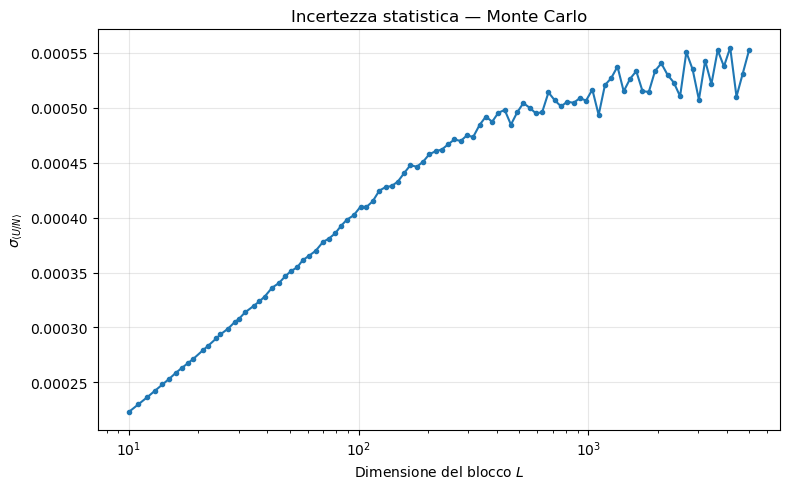

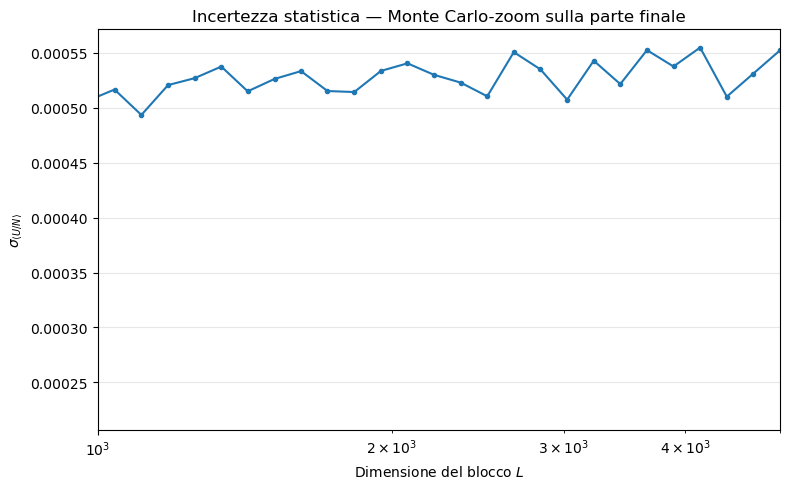

In [5]:
# Dimensioni dei blocchi tra 10 e 5000
L_values = np.unique(
    np.logspace(np.log10(10), np.log10(5000), 100).astype(int)
)

errors_mc = []

for L in L_values:

    # Numero di blocchi completi
    N = M // L

    # Utilizziamo solo i dati appartenenti a blocchi completi
    data = u_mc[:N*L]

    # Costruzione dei blocchi
    blocks = data.reshape(N, L)

    # Media di U/N in ogni blocco
    block_means = np.mean(blocks, axis=1)

    # Errore statistico sulla media
    error = np.std(block_means, ddof=1) / np.sqrt(N)

    errors_mc.append(error)


plt.figure(figsize=(8, 5))

plt.plot(L_values, errors_mc, marker="o", markersize=3)

plt.xscale("log")

plt.xlabel(r"Dimensione del blocco $L$")
plt.ylabel(r"$\sigma_{\langle U/N\rangle}$")
plt.title("Incertezza statistica — Monte Carlo")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.figure(figsize=(8, 5))

plt.plot(L_values, errors_mc, marker="o", markersize=3)

plt.xscale("log")
plt.xlim(1000, 5000)
plt.xlabel(r"Dimensione del blocco $L$")
plt.ylabel(r"$\sigma_{\langle U/N\rangle}$")
plt.title("Incertezza statistica — Monte Carlo-zoom sulla parte finale")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Commento ai risultati Monte Carlo

La funzione di autocorrelazione $C(\tau)$ decresce rapidamente all'aumentare del lag $\tau$. Le correlazioni diventano molto piccole dopo circa $100$ MC step e risultano sostanzialmente trascurabili per lag dell'ordine di alcune centinaia di step.

Questo comportamento è coerente con il risultato ottenuto tramite data blocking. Per piccoli valori di $L$ l'incertezza statistica risulta sottostimata, poiché le misure contenute nei blocchi sono ancora fortemente correlate. Aumentando la dimensione del blocco, l'incertezza cresce fino a raggiungere approssimativamente un plateau per

$$
L\gtrsim500-1000.
$$

In questa regione si ottiene un'incertezza dell'ordine di

$$
\sigma_{\langle U/N\rangle}\sim5\times10^{-4}.
$$

Il raggiungimento del plateau indica che la dimensione dei blocchi è ormai sufficientemente grande rispetto al tempo di correlazione e che le medie dei diversi blocchi possono essere considerate approssimativamente indipendenti.

## Molecular Dynamics — equilibrazione e scelta della temperatura iniziale

La simulazione di Molecular Dynamics viene eseguita nell'ensemble microcanonico $NVE$, utilizzando l'algoritmo di Verlet con passo temporale

$$
dt=0.001.
$$

A differenza della simulazione Monte Carlo $NVT$, nella Molecular Dynamics la temperatura non viene mantenuta fissa durante l'evoluzione. Una volta assegnate le velocità iniziali, viene infatti conservata l'energia totale

$$
E=K+U,
$$

mentre energia cinetica e potenziale possono scambiarsi tra loro. Di conseguenza, la temperatura inserita inizialmente non coincide necessariamente con la temperatura raggiunta dal sistema dopo l'equilibrazione.

Partendo dalla configurazione cristallina, una prima simulazione con

$$
T_0=1.1
$$

ha portato, dopo il transiente iniziale, a una temperatura di equilibrio di circa

$$
T_{\mathrm{eq}}\simeq0.56-0.57,
$$

quindi molto inferiore al valore desiderato $T=1.1$.

Per stimare una temperatura iniziale più adatta è stata utilizzata l'energia potenziale media ottenuta dalla simulazione Monte Carlo alla temperatura $T=1.1$,

$$
\left\langle\frac{U}{N}\right\rangle_{\mathrm{MC}}\simeq-5.461.
$$

Per un sistema classico tridimensionale, l'energia cinetica media per particella alla temperatura desiderata è

$$
\frac{K}{N}=\frac{3}{2}T.
$$

Per $T=1.1$ si ottiene quindi

$$
\frac{K}{N}\simeq1.65.
$$

L'energia totale per particella associata allo stato desiderato può essere stimata come

$$
\frac{E}{N}
\simeq
\frac{U}{N}+\frac{K}{N}
\simeq
-5.461+1.65
\simeq-3.811.
$$

Nel primo tentativo MD si era invece ottenuta un'energia totale di circa

$$
\frac{E}{N}\simeq-5.129.
$$

Era quindi necessario fornire al sistema una maggiore energia cinetica iniziale. La differenza di energia è

$$
\Delta E\simeq-3.811-(-5.129)=1.318,
$$

e, utilizzando

$$
\Delta\left(\frac{K}{N}\right)=\frac{3}{2}\Delta T,
$$

si ricava

$$
\Delta T\simeq\frac{2}{3}\,1.318\simeq0.88.
$$

La temperatura iniziale stimata risulta quindi

$$
T_0\simeq1.1+0.88\simeq1.98.
$$

È stato quindi scelto

$$
T_0=2.0.
$$

Con questa inizializzazione, dopo l'equilibrazione la temperatura si stabilizza attorno a

$$
\boxed{\langle T\rangle\simeq1.11},
$$

in buon accordo con la temperatura richiesta $T=1.1$.

La configurazione equilibrata è stata infine utilizzata come punto di partenza per una simulazione di produzione di

$$
M=5\times10^5
$$

step MD, durante la quale sono stati registrati i valori istantanei di $U/N$.

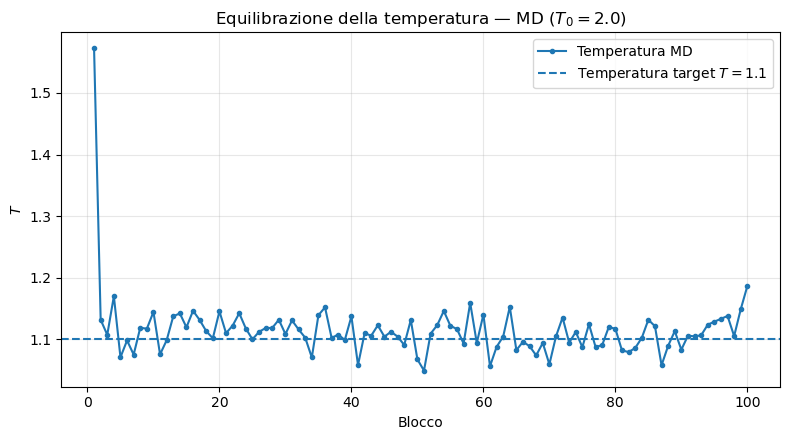

In [10]:
# Temperatura durante l'equilibrazione MD
temp_data = np.loadtxt(
    "Esercizio_07.2/NSL_SIMULATOR/OUTPUT/temperature_MD_equilibration.dat",
    comments="#"
)

block = temp_data[:, 0]
T_block = temp_data[:, 1]

plt.figure(figsize=(8, 4.5))

plt.plot(block, T_block, marker="o", markersize=3,
         label="Temperatura MD")

plt.axhline(1.1, linestyle="--",
            label=r"Temperatura target $T=1.1$")

plt.xlabel("Blocco")
plt.ylabel(r"$T$")
plt.title(r"Equilibrazione della temperatura — MD ($T_0=2.0$)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

Partendo da una temperatura iniziale

$$
T_0=2.0,
$$

la temperatura diminuisce durante il transiente iniziale e successivamente oscilla attorno al valore desiderato

$$
\langle T\rangle\simeq1.11,
$$

in buon accordo con la temperatura target $T=1.1$. La configurazione finale di questa fase è stata quindi utilizzata come stato iniziale per la produzione MD.

Numero di misure = 500000
<U/N> = -5.442778


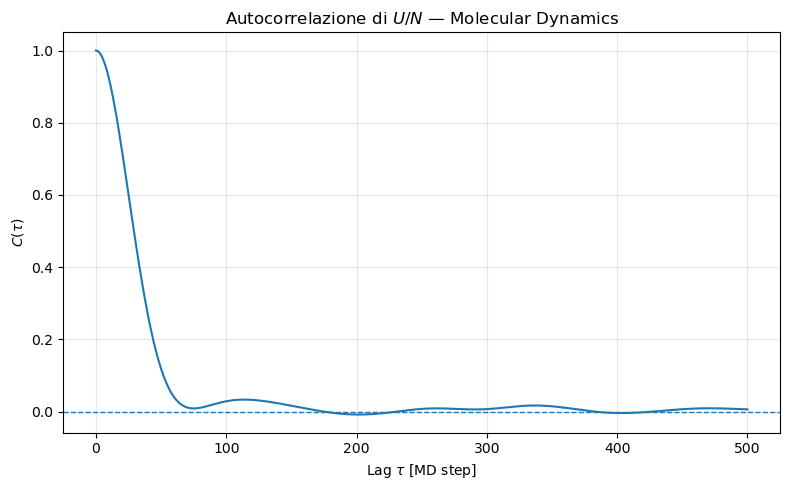

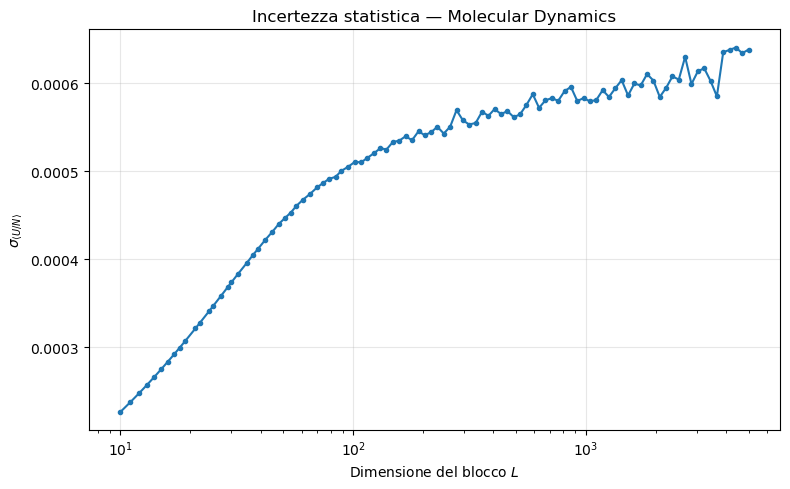

In [8]:
# Lettura della produzione MD
data_md = np.loadtxt(
    "Esercizio_07.2/NSL_SIMULATOR/OUTPUT/instantaneous_potential_energy_MD_production.dat",
    comments="#"
)

step_md = data_md[:, 0]
u_md = data_md[:, 1]

M_md = len(u_md)

print("Numero di misure =", M_md)
print(f"<U/N> = {np.mean(u_md):.6f}")

max_lag = 500

C_md = autocorrelation(u_md, max_lag)
tau_md = np.arange(max_lag + 1)

plt.figure(figsize=(8, 5))

plt.plot(tau_md, C_md)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel(r"Lag $\tau$ [MD step]")
plt.ylabel(r"$C(\tau)$")
plt.title(r"Autocorrelazione di $U/N$ — Molecular Dynamics")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

L_values = np.unique(
    np.logspace(np.log10(10), np.log10(5000), 100).astype(int)
)

errors_md = []

for L in L_values:

    N = M_md // L

    data = u_md[:N*L]

    blocks = data.reshape(N, L)

    block_means = np.mean(blocks, axis=1)

    error = np.std(block_means, ddof=1) / np.sqrt(N)

    errors_md.append(error)


plt.figure(figsize=(8, 5))

plt.plot(L_values, errors_md, marker="o", markersize=3)

plt.xscale("log")

plt.xlabel(r"Dimensione del blocco $L$")
plt.ylabel(r"$\sigma_{\langle U/N\rangle}$")
plt.title("Incertezza statistica — Molecular Dynamics")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Analisi statistica della produzione MD

La funzione di autocorrelazione mostra che valori di $U/N$ misurati a pochi step di distanza sono fortemente correlati. Questo è naturale, poiché il piccolo passo temporale $dt=0.001$ determina variazioni molto piccole della configurazione tra due step consecutivi.

L'autocorrelazione diminuisce rapidamente e diventa molto piccola per lag dell'ordine di

$$
\tau\simeq70-100 \text{ MD step},
$$

mentre per lag maggiori presenta soltanto piccole oscillazioni attorno allo zero.

Anche il data blocking evidenzia l'effetto delle correlazioni. Per blocchi piccoli l'incertezza statistica è sottostimata; aumentando $L$, l'errore cresce fino a stabilizzarsi approssimativamente per

$$
L\gtrsim500-1000,
$$

su valori dell'ordine di

$$
\sigma_{\langle U/N\rangle}\sim6\times10^{-4}.
$$

Il raggiungimento del plateau indica che, per queste dimensioni, i blocchi sono sufficientemente lunghi rispetto alla scala delle correlazioni.

## Confronto tra Monte Carlo e Molecular Dynamics

Le due simulazioni producono sequenze di configurazioni secondo dinamiche molto diverse. Nel Monte Carlo l'evoluzione è stocastica ed è determinata dall'algoritmo di Metropolis, mentre nella Molecular Dynamics l'evoluzione è deterministica ed è ottenuta integrando le equazioni del moto.

È quindi interessante confrontare direttamente sia la funzione di autocorrelazione sia l'incertezza statistica ottenuta mediante data blocking.

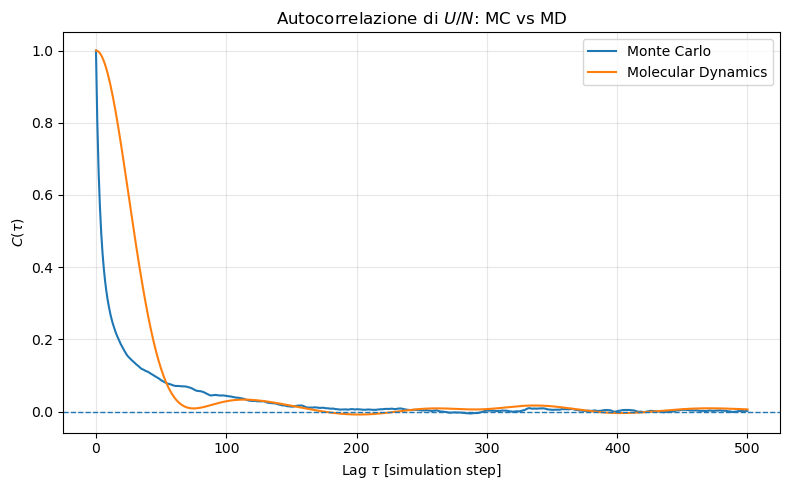

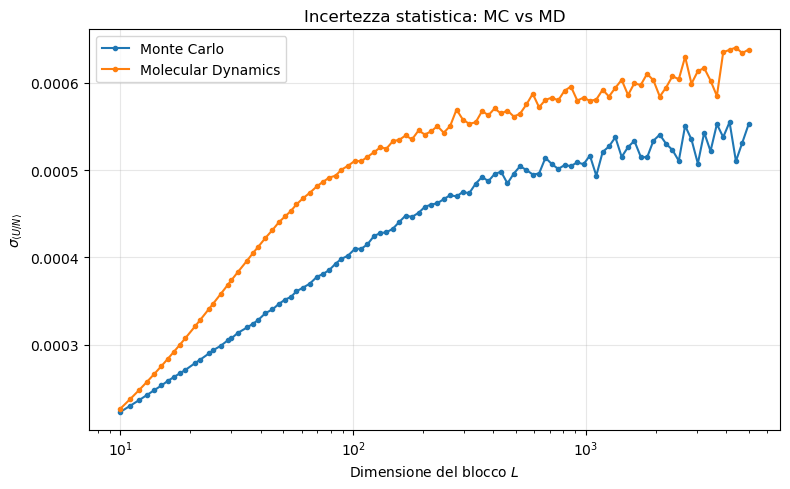

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(tau, C_mc, label="Monte Carlo")
plt.plot(tau_md, C_md, label="Molecular Dynamics")

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel(r"Lag $\tau$ [simulation step]")
plt.ylabel(r"$C(\tau)$")
plt.title(r"Autocorrelazione di $U/N$: MC vs MD")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.figure(figsize=(8, 5))

plt.plot(L_values, errors_mc,
         marker="o", markersize=3,
         label="Monte Carlo")

plt.plot(L_values, errors_md,
         marker="o", markersize=3,
         label="Molecular Dynamics")

plt.xscale("log")

plt.xlabel(r"Dimensione del blocco $L$")
plt.ylabel(r"$\sigma_{\langle U/N\rangle}$")
plt.title("Incertezza statistica: MC vs MD")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Confronto tra Monte Carlo e Molecular Dynamics



Nel Monte Carlo l'autocorrelazione di $U/N$ diminuisce molto rapidamente nei primi step, mentre nella Molecular Dynamics rimane inizialmente più elevata. Questo comportamento è naturale: nella MD, con un passo temporale piccolo $dt=0.001$, due configurazioni successive sono molto simili tra loro, mentre nel Monte Carlo un singolo step comprende numerosi tentativi di spostamento delle particelle.

In entrambi i casi l'autocorrelazione diventa comunque molto piccola dopo alcune centinaia di step.

Il confronto tramite data blocking mostra inoltre che l'incertezza statistica cresce con la dimensione del blocco $L$ fino a raggiungere progressivamente un plateau. Per entrambe le simulazioni questo avviene approssimativamente per

$$
L\gtrsim500-1000.
$$

Il valore asintotico dell'incertezza risulta leggermente maggiore per la Molecular Dynamics,

$$
\sigma_{\langle U/N\rangle}^{\mathrm{MD}}
\sim 6\times10^{-4},
$$

rispetto al Monte Carlo,

$$
\sigma_{\langle U/N\rangle}^{\mathrm{MC}}
\sim 5\times10^{-4}.
$$

Questo indica che, a parità di numero di misure registrate, la sequenza prodotta dalla Molecular Dynamics presenta complessivamente correlazioni statistiche leggermente più rilevanti.

Va infine osservato che il confronto dell'autocorrelazione in funzione del numero di step è principalmente qualitativo: un MC step e un MD step non rappresentano la stessa scala temporale. Nella MD lo step corrisponde infatti a un intervallo fisico $dt=0.001$, mentre nel Monte Carlo rappresenta un passo della catena di Markov.

# Esercizio 07.3 — Funzione di distribuzione radiale

Il codice C++ del simulatore è stato esteso introducendo il calcolo della
**funzione di distribuzione radiale** $g(r)$, che descrive la struttura
microscopica del sistema attraverso la distribuzione delle distanze
tra coppie di particelle.

Durante la simulazione vengono calcolate le distanze tra tutte le
coppie di particelle, applicando le condizioni periodiche al contorno
e suddividendo l'intervallo $[0,L/2]$ in un numero prefissato di bin.

Per ogni configurazione viene costruito un istogramma delle distanze,
successivamente normalizzato rispetto alla densità e al volume
dei gusci sferici:

$$
g(r)=\frac{n(r)}{\rho N\,\Delta V(r)}
$$

dove $n(r)$ rappresenta il numero di coppie ordinate nel bin,
$\rho$ la densità e $\Delta V(r)$ il volume del guscio sferico
corrispondente.

Le medie e le relative incertezze statistiche vengono calcolate
mediante **data blocking**.

La funzione $g(r)$ così ottenuta viene utilizzata nell'esercizio 07.4
per confrontare la struttura microscopica del sistema simulato
mediante Monte Carlo e Molecular Dynamics.

# Esercizio 07.4 — Simulazione di un sistema di particelle di Argon

Si considera un sistema di $N = 256$ particelle di  Argon   descritto dal potenziale di Lennard-Jones, con parametri

$$
\sigma = 0.34\,\mathrm{nm},
\qquad
\frac{\varepsilon}{k_B}=120\,\mathrm{K},
\qquad
m=39.948\,\mathrm{amu}.
$$

La simulazione viene eseguita in unità ridotte di Lennard-Jones, nelle condizioni della fase liquida

$$
\rho^*=0.8,
\qquad
T^*=1.1,
\qquad
r_c^*=2.5.
$$

Vengono confrontati due differenti metodi di simulazione:

- Monte Carlo nell'ensemble canonico $NVT$;
- Molecular Dynamics nell'ensemble microcanonico $NVE$.

Per entrambi i metodi vengono calcolati:

$$
\frac{U}{N},
\qquad
P,
\qquad
g(r),
$$

riportando i valori medi e le relative incertezze statistiche ottenute mediante data blocking.

## Confronto Monte Carlo e Molecular Dynamics

Dopo aver equilibrato separatamente le simulazioni Monte Carlo $NVT$ e Molecular Dynamics $NVE$, sono state eseguite due simulazioni di produzione nelle condizioni della fase liquida

$$
\rho^*=0.8,
\qquad
T^*\simeq1.1,
\qquad
r_c^*=2.5.
$$

Per entrambe le simulazioni vengono confrontati:

$$
\frac{U}{N},
\qquad
P,
\qquad
g(r),
$$

con le relative incertezze statistiche ottenute mediante il metodo del data blocking.

Monte Carlo:
<U/N> = -5.461730 ± 0.001062

Molecular Dynamics:
<U/N> = -5.443010 ± 0.001282


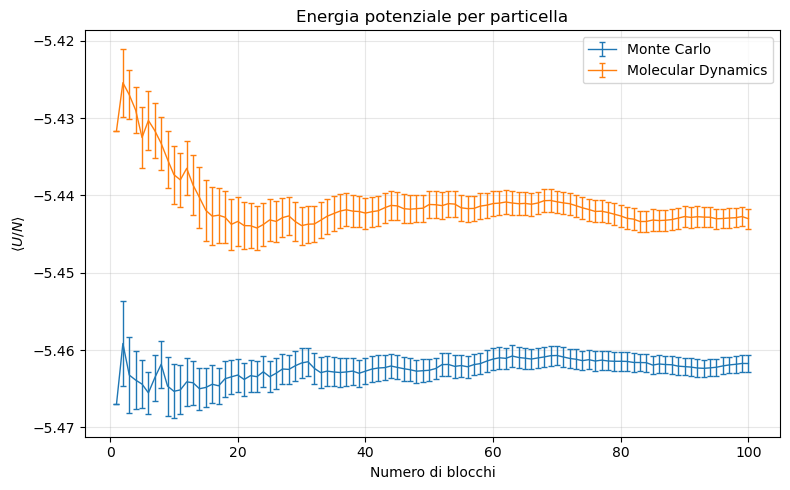

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Lettura dei dati
energy_mc = np.loadtxt(
    "Esercizio_07.2/NSL_SIMULATOR/OUTPUT/potential_energy_MC_argon.dat",
    comments="#"
)

energy_md = np.loadtxt(
    "Esercizio_07.2/NSL_SIMULATOR/OUTPUT/potential_energy_MD_argon.dat",
    comments="#"
)

# Colonne:
# 0 -> blocco
# 1 -> media del singolo blocco
# 2 -> media progressiva
# 3 -> errore progressivo

blocks_mc = energy_mc[:, 0]
u_mc = energy_mc[:, 2]
err_mc = energy_mc[:, 3]

blocks_md = energy_md[:, 0]
u_md = energy_md[:, 2]
err_md = energy_md[:, 3]

# Risultati finali
print("Monte Carlo:")
print(f"<U/N> = {u_mc[-1]:.6f} ± {err_mc[-1]:.6f}")

print("\nMolecular Dynamics:")
print(f"<U/N> = {u_md[-1]:.6f} ± {err_md[-1]:.6f}")

# Grafico
plt.figure(figsize=(8, 5))

plt.errorbar(
    blocks_mc, u_mc, yerr=err_mc,
    label="Monte Carlo",
    capsize=2,
    linewidth=1
)

plt.errorbar(
    blocks_md, u_md, yerr=err_md,
    label="Molecular Dynamics",
    capsize=2,
    linewidth=1
)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\langle U/N\rangle$")
plt.title("Energia potenziale per particella")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

### Energia potenziale per particella

Entrambe le simulazioni mostrano una buona convergenza della media progressiva dell'energia potenziale per particella.

La simulazione Monte Carlo converge a un valore circa pari a

$$
\left\langle \frac{U}{N}\right\rangle_{\mathrm{MC}}
\simeq -5.462,
$$

mentre la Molecular Dynamics converge a

$$
\left\langle \frac{U}{N}\right\rangle_{\mathrm{MD}}
\simeq -5.443.
$$

I due risultati sono vicini, ma non risultano compatibili entro le sole incertezze statistiche.

La differenza è riconducibile principalmente al fatto che le due simulazioni non si trovano esattamente nello stesso stato termodinamico. Nella simulazione Monte Carlo la temperatura è fissata a

$$
T=1.1,
$$

mentre nella simulazione MD si ottiene

$$
\langle T\rangle_{\mathrm{MD}}
=1.1112\pm0.0008.
$$

La temperatura leggermente maggiore della MD porta a un'energia potenziale mediamente meno negativa. Per un sistema finito, anche il campionamento nei due ensemble differenti, $NVT$ e $NVE$, può introdurre ulteriori piccole differenze.

Monte Carlo:
<P> = 1.434730 ± 0.005485

Molecular Dynamics:
<P> = 1.543690 ± 0.006796


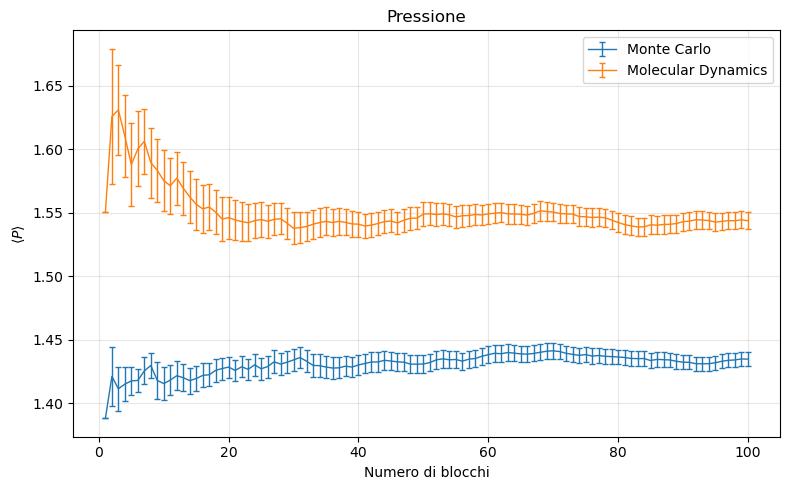

In [22]:
pressure_mc = np.loadtxt(
    "Esercizio_07.2/NSL_SIMULATOR/OUTPUT/pressure_MC_argon.dat",
    comments="#"
)

pressure_md = np.loadtxt(
    "Esercizio_07.2/NSL_SIMULATOR/OUTPUT/pressure_MD_argon.dat",
    comments="#"
)

blocks_mc = pressure_mc[:, 0]
p_mc = pressure_mc[:, 2]
err_p_mc = pressure_mc[:, 3]

blocks_md = pressure_md[:, 0]
p_md = pressure_md[:, 2]
err_p_md = pressure_md[:, 3]

print("Monte Carlo:")
print(f"<P> = {p_mc[-1]:.6f} ± {err_p_mc[-1]:.6f}")

print("\nMolecular Dynamics:")
print(f"<P> = {p_md[-1]:.6f} ± {err_p_md[-1]:.6f}")

plt.figure(figsize=(8, 5))

plt.errorbar(
    blocks_mc, p_mc, yerr=err_p_mc,
    label="Monte Carlo",
    capsize=2,
    linewidth=1
)

plt.errorbar(
    blocks_md, p_md, yerr=err_p_md,
    label="Molecular Dynamics",
    capsize=2,
    linewidth=1
)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\langle P\rangle$")
plt.title("Pressione")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

### Pressione

Anche la pressione mostra una buona convergenza delle medie progressive.

Si ottengono approssimativamente

$$
P_{\mathrm{MC}}\simeq1.43,
\qquad
P_{\mathrm{MD}}\simeq1.54.
$$

Come per l'energia potenziale, i due valori non risultano compatibili entro le sole incertezze statistiche.

Lo scostamento è legato principalmente alla piccola differenza tra gli stati termodinamici campionati: nel Monte Carlo la temperatura è fissata a $T=1.1$, mentre nella Molecular Dynamics la temperatura media è leggermente superiore.

La pressione è particolarmente sensibile a questa differenza perché contiene sia il contributo ideale sia il contributo viriale dovuto alle interazioni tra le particelle,

$$
P=\rho T+P_{\mathrm{vir}}+P_{\mathrm{tail}}.
$$

Anche in questo caso, per un sistema finito, la differenza tra gli ensemble $NVT$ e $NVE$ può contribuire allo scostamento osservato.

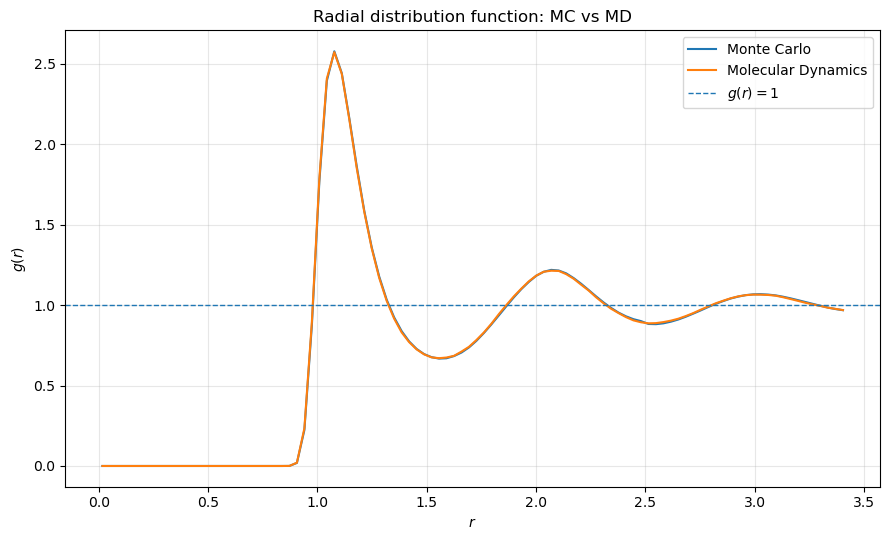

In [28]:
# Radial distribution function
gofr_mc = np.loadtxt(
    "Esercizio_07.2/NSL_SIMULATOR/OUTPUT/gofr_MC_argon.dat",
    comments="#"
)

gofr_md = np.loadtxt(
    "Esercizio_07.2/NSL_SIMULATOR/OUTPUT/gofr_MD_argon.dat",
    comments="#"
)

# Colonne:
# 0 -> distanza r
# 1 -> <g(r)>
# 2 -> errore

r_mc = gofr_mc[:, 0]
g_mc = gofr_mc[:, 1]
err_g_mc = gofr_mc[:, 2]

r_md = gofr_md[:, 0]
g_md = gofr_md[:, 1]
err_g_md = gofr_md[:, 2]

plt.figure(figsize=(9, 5.5))

# Monte Carlo
plt.plot(
    r_mc, g_mc,
    label="Monte Carlo"
)

plt.fill_between(
    r_mc,
    g_mc - err_g_mc,
    g_mc + err_g_mc,
    alpha=0.20
)

# Molecular Dynamics
plt.plot(
    r_md, g_md,
    label="Molecular Dynamics"
)

plt.fill_between(
    r_md,
    g_md - err_g_md,
    g_md + err_g_md,
    alpha=0.20
)

plt.axhline(
    1.0,
    linestyle="--",
    linewidth=1,
    label=r"$g(r)=1$"
)

plt.xlabel(r"$r$")
#plt.ylim(0.35,0.85) #ZOOM
#plt.xlim(1.5,1.6) #ZOOM
plt.ylabel(r"$g(r)$")
plt.title("Radial distribution function: MC vs MD")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

### Radial distribution function

Le funzioni di distribuzione radiale ottenute mediante Monte Carlo e Molecular Dynamics risultano praticamente sovrapposte lungo tutto l'intervallo di distanze considerato.

Per piccole distanze si osserva

$$
g(r)\simeq0,
$$

a causa della forte repulsione a corto raggio del potenziale di Lennard-Jones.

Il primo picco, molto pronunciato, compare attorno a

$$
r\simeq1.1,
$$

e rappresenta la shell dei primi vicini. A distanze maggiori compaiono oscillazioni via via meno intense, associate alle shell successive.

Per grandi distanze la funzione tende progressivamente a

$$
g(r)\to1,
$$

come atteso per un liquido omogeneo in cui le correlazioni tra particelle diventano trascurabili.

L'eccellente accordo tra Monte Carlo e Molecular Dynamics mostra che, nonostante le differenze nei valori medi di energia potenziale e pressione, i due metodi descrivono praticamente la stessa struttura microscopica del liquido.

### Conclusioni

Le simulazioni Monte Carlo $NVT$ e Molecular Dynamics $NVE$ mostrano entrambe una buona convergenza statistica nelle condizioni della fase liquida considerate.

Le stime dell'energia potenziale per particella e della pressione presentano un piccolo scostamento sistematico tra i due metodi. Questo è dovuto principalmente al fatto che le simulazioni non si trovano esattamente nello stesso stato termodinamico: nella MD la temperatura media risulta leggermente superiore al valore $T=1.1$ imposto nel Monte Carlo. Per un sistema finito, anche il diverso ensemble statistico può contribuire a queste differenze.

Al contrario, le funzioni di distribuzione radiale $g(r)$ ottenute con Monte Carlo e Molecular Dynamics risultano quasi perfettamente sovrapposte. I due metodi descrivono quindi in modo sostanzialmente equivalente la struttura microscopica del liquido.

Nel complesso, il confronto mostra che MC e MD forniscono una descrizione coerente dello stesso sistema di Lennard-Jones, pur presentando piccole differenze nelle quantità termodinamiche dovute alle diverse condizioni di campionamento.